In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
from scipy.stats import norm
import os

from model import *
from data import generate_gmm_data, generate_random_data
from train_utils import train

from plot import *
from utils import *


In [2]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
print(device)

cpu


In [3]:
relu = lambda X: np.maximum(X, 0)
d_relu = lambda X: np.maximum(np.sign(X), 0)

elu = lambda X, alpha=1.0: ( alpha * (np.exp(X) - 1) ) * (X <= 0) + (X * (X > 0))
d_elu = lambda X, alpha=1.0: ( alpha * np.exp(X) ) * (X <= 0) + (X > 0)

gelu = lambda X: X * norm.cdf(X)
d_gelu = lambda X: norm.cdf(X) + X * norm.pdf(X)

sigmoid = lambda X: 1 / (1 + np.exp(-X))
d_sigmoid = lambda X: sigmoid(X) * (1 - sigmoid(X))

silu = lambda X: X * sigmoid(X)
d_silu = lambda X: sigmoid(X) + X * d_sigmoid(X)

leaky_relu = lambda X, slope=0.01: slope * np.minimum(X, 0) + np.maximum(X, 0)
d_leaky_relu = lambda X, slope=0.01: slope * (X <= 0) + (X > 0).astype(float)

identity = lambda X: X
d_identity = lambda X: np.ones(X.shape)

abs_ = lambda X: np.abs(X)
d_abs_ = lambda X: -1 * (X <= 0) + (X > 0)

softplus = lambda X: np.log(1 + np.exp(X))
d_softplus = lambda X: sigmoid(X)

leaky_softplus = lambda X, slope=0.01: slope * X + (1 - slope) * (softplus(X) - np.log(2))
d_leaky_softplus = lambda X, slope=0.01: slope + (1 - slope) * (d_softplus(X))


smooth_abs = lambda X, beta = 10: (2 / beta) * softplus(X) - X - ( (2 / beta) * np.log(2) )
d_smooth_abs = lambda X, beta = 10: (2 / beta) * d_softplus(X) - 1

custom_activations_map = {'ReLU': [relu, d_relu],
               'Leaky-Softplus': [leaky_softplus, d_leaky_softplus], 
               'ELU': [elu, d_elu],
               'GELU': [gelu, d_gelu],
               'SiLU': [silu, d_silu],
               'Leaky-ReLU': [leaky_relu, d_leaky_relu],
               'Abs': [abs_, d_abs_],
               'SmoothAbs': [smooth_abs, d_smooth_abs],
               'Identity': [identity, d_identity]}

In [4]:
optimizer_map = {'SGD': optim.SGD,
                'Adam': optim.Adam}

# Model Training

In [5]:
def get_data(d: int, 
             K: int, 
             N_k: int, 
             nu: float = 1.0,
             normalize_: bool = False, 
             orthogonalize_: bool = False):
    
    
    N = K * N_k
    
    # d > N --> random Gaussian data
    if d > N:
        train_set, train_loader, _ = generate_random_data(d, 
                                                       K, 
                                                       N_k, 
                                                       orthogonalize_ = orthogonalize_, 
                                                       normalize_ = normalize_)
        val_loader = train_loader 
    
    # N > d --> Gaussian mixture data
    elif N > d:
        train_set, train_loader, _ = generate_gmm_data(d, 
                                                    K,
                                                    N_k, 
                                                    nu=nu,
                                                    whiten_ = whiten_, 
                                                    normalize_ = normalize_)
        val_loader = train_loader
    
    
    X = train_set.samples.T
    Y = train_set.targets.T
    
    return train_loader, val_loader, X, Y

In [6]:
def train_model(num_layers: int,
                data_dim: int, 
                hidden_dim: int, 
                num_classes: int, 
                act_fn_str: str, 
                train_loader, 
                val_loader, 
                epochs, 
                lr, 
                freq,
                loss_fn, 
                optimizer_type='SGD', 
                freeze_last_layer=True, 
                residual=False, 
                batchnorm=False, 
                init_method='orthogonal',
                init_scale=1):
    
    
    # Train model
    model = MLP(num_layers, 
                data_dim, 
                hidden_dim, 
                num_classes, 
                act_fn_str, 
                freeze_last_layer=freeze_last_layer,
                last_layer_init_method='uniform',
                residual=residual, 
                batchnorm=batchnorm, 
                init_method=init_method, 
                init_scale=init_scale)

    model = model.to(device)

    # Training
    criterion = loss_map[loss_fn]
    optimizer = optimizer_map[optimizer_type](model.parameters(), lr=lr, weight_decay=0)
    scheduler = None
    #scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, epochs, eta_min=0)
    results = train(model, 
                    criterion, 
                    optimizer, 
                    train_loader, 
                    val_loader, 
                    epochs, 
                    device,
                    scheduler=scheduler, 
                    return_weights=True,
                    return_grads=True,
                    return_outs=True)

    grads = results['all_grads']
    train_losses = results['train_losses']
    weights = results['all_weights']
    
    outs = results['all_outs']
    
    return grads, weights, train_losses, outs

# Top singular values

In [7]:
'''
Helper function to calculate the norm of each component in the weight matrix 
'''
def grad_norm_and_svals_ratio(grads, K, init_scale, epochs):
    
    max_top_sval_ratio = np.zeros((epochs))
    grad_norm_ratio = np.zeros((epochs))
    max_tail_svals = np.zeros((epochs))
    
    G1_0 = grads[0][0]
    s0_top = np.linalg.svd(G1_0, compute_uv=False)[:K]
    
    for t in range(epochs):
        G1_t = grads[t][0]
        
        #print(np.linalg.norm(G1_t, ord='fro'))
        
        # Gradient norm
        grad_norm_ratio[t] = np.linalg.norm(G1_t, ord='fro') / np.linalg.norm(G1_0, ord='fro')
        
        # Singular values
        st_top = np.linalg.svd(G1_t, compute_uv=False)[:(K + 1)]
        
        sval_ratio = st_top[:-1] / s0_top
        max_top_sval_ratio[t] = np.max(sval_ratio)
        
        max_tail_svals[t] = st_top[-1]
        
        
    return grad_norm_ratio, max_top_sval_ratio, max_tail_svals 

In [8]:
reduction = 'sum'
loss_map = {
    'ce_loss': nn.CrossEntropyLoss(reduction=reduction),
    'mse_loss': nn.MSELoss(reduction=reduction)
}

data_type_map = {
    'gmm': 'GMM', 
    'uos': 'UoS',
    'random': 'Random'
}

In [9]:
# Data setup
d = 64 #512 # Ambient dim
m = 72 #768
K = 4 # Number of classes
N_k = 250
N = N_k * K
nu = np.sqrt(3)

# Model setup
L = 2
act_fn_strs = ['ELU', 'GELU', 'SiLU']
residual = False
batchnorm = False
freeze_last_layer = True
init_method = 'orthogonal'
init_scale = 1e-2 #[1e-2, 1e-4, 1e-6]

whiten_ = True
normalize_ = False
orthogonalize_ = False

# Training setup
epochs = 250
lrs = [1e-3, 5e-3, 5e-3] #, 5e-4] #, 1e-4] #, 5e-4] #, 5e-3] #, 1e-3] #, 1e-5]
freq = 1
optimizer_type = 'SGD'
#loss_fn = 'ce_loss'
loss_fn = 'mse_loss'

save = True
savefig_dir = './figs/assumptions/'
if not os.path.exists(savefig_dir):
    os.makedirs(savefig_dir)

    
run = False 


In [10]:
if run: 
    trials = 10


    grad_norm_ratio = np.zeros((trials, len(act_fn_strs), epochs))
    max_top_sval_ratio = np.zeros((trials, len(act_fn_strs), epochs))

    max_tail_sval = np.zeros((trials, len(act_fn_strs), epochs))
    W2YX_Kth_sval = np.zeros((trials, len(act_fn_strs)))


    train_losses = np.zeros((trials, len(act_fn_strs), epochs))

    for j, act_fn_str in enumerate(act_fn_strs):
        lr = lrs[j]

        for i in range(trials):
            # Create data
            train_loader, val_loader, X, Y = get_data(d, K, N_k, nu, whiten_, normalize_)

            print("=== TRIAL " + str(i) + " ===")

            # Train model
            grads, weights, train_losses_trial, outs = train_model(L, d, m, K, act_fn_str, 
                                                             train_loader, 
                                                             val_loader, 
                                                             epochs, 
                                                             lr, 
                                                             freq, 
                                                             loss_fn, 
                                                             optimizer_type=optimizer_type,
                                                             freeze_last_layer=freeze_last_layer, 
                                                             residual=residual,
                                                             batchnorm=batchnorm,
                                                             init_method=init_method,
                                                             init_scale=init_scale)


            # Plot train loss
            plot_train_losses(train_losses_trial, act_fn_str, d, K, None, savefig=False)
            train_losses[i, j, :] = train_losses_trial

            # Calculate gradient norms and singular values
            trial_grad_norm_ratio, trial_max_top_sval_ratio, trial_max_tail_sval = grad_norm_and_svals_ratio(grads, K, init_scale, epochs)

            # Gradient norm and singular value ratios
            grad_norm_ratio[i, j, :] = trial_grad_norm_ratio
            max_top_sval_ratio[i, j, :] = trial_max_top_sval_ratio  

            # Max tail singular value
            W2 = weights[0][1]

            max_tail_sval[i, j, :] = trial_max_tail_sval
            W2YX_Kth_sval[i, j] = np.linalg.svd(W2.T @ Y @ X.T, compute_uv=False)[K - 1]
            
        
    # Save results 
    np.savez(os.path.join(savefig_dir, 'grad_norm_ratio.npz'), grad_norm_ratio=grad_norm_ratio)
    np.savez(os.path.join(savefig_dir, 'max_top_sval_ratio.npz'), max_top_sval_ratio=max_top_sval_ratio)

    np.savez(os.path.join(savefig_dir, 'max_tail_sval.npz'), max_tail_sval=max_tail_sval)
    np.savez(os.path.join(savefig_dir, 'W2YX_Kth_sval.npz'), W2YX_Kth_sval=W2YX_Kth_sval)
    

else:
    grad_norm_ratio = np.load(os.path.join(savefig_dir, 'grad_norm_ratio.npz'))['grad_norm_ratio']
    max_top_sval_ratio = np.load(os.path.join(savefig_dir, 'max_top_sval_ratio.npz'))['max_top_sval_ratio']
    max_tail_sval = np.load(os.path.join(savefig_dir, 'max_tail_sval.npz'))['grad_norm_ratio']
    W2YX_Kth_sval = np.load(os.path.join(savefig_dir, 'W2YX_Kth_sval.npz'))['max_top_sval_ratio']




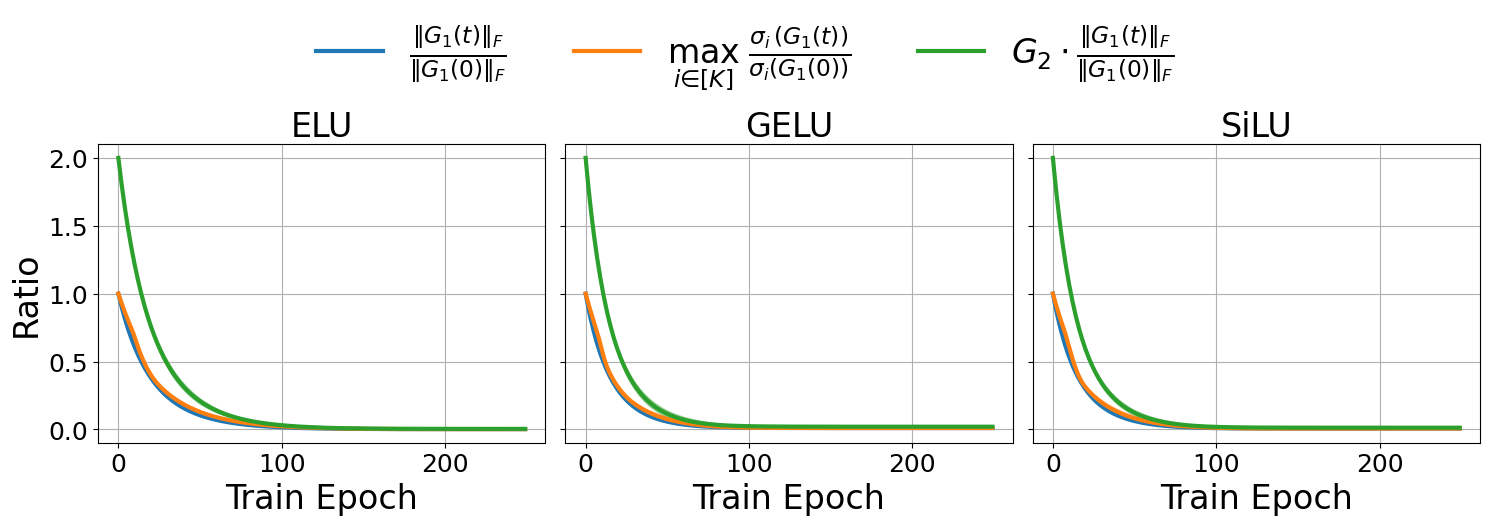

In [11]:
# Mean and stdev of weight decomposition norms across trials
mean_grad_norm_ratio = np.mean(grad_norm_ratio, axis=0)
std_grad_norm_ratio = np.std(grad_norm_ratio, axis=0)

mean_max_top_sval_ratio = np.mean(max_top_sval_ratio, axis=0)
std_max_top_sval_ratio = np.std(max_top_sval_ratio, axis=0)


x_range = np.arange(epochs)

n_plots = len(act_fn_strs)
fig, axes = plt.subplots(
    1,
    n_plots,
    figsize=(5 * n_plots, 5),
    sharey=True
)

# Make axes iterable even if n_plots == 1
if n_plots == 1:
    axes = [axes]

legend_handles = None
legend_labels = None

for i, act_fn_str in enumerate(act_fn_strs):
    ax = axes[i]
    
    # Gradient norm 
    label = r'$\frac{\| G_1(t) \|_F}{\| G_1(0) \|_F}$'
    line, = ax.plot(
        x_range, 
        mean_grad_norm_ratio[i, :],
        linewidth=3, 
        label=label
    )
    
    ax.fill_between(
        x_range, 
        mean_grad_norm_ratio[i, :] - std_grad_norm_ratio[i, :],
        mean_grad_norm_ratio[i, :] + std_grad_norm_ratio[i, :],
        alpha=0.5
    )
    
    if legend_handles is None:
        legend_handles = []
        legend_labels = []

    if label not in legend_labels:
        legend_handles.append(line)
        legend_labels.append(label)
        
    
    # Singular values
    label = r'$\max_{i \in [K]} \; \frac{\sigma_i(G_1(t))}{\sigma_i(G_1(0))}$'
    line, = ax.plot(
        x_range, 
        mean_max_top_sval_ratio[i, :],
        linewidth=3, 
        label=label
    )
    
    ax.fill_between(
        x_range, 
        mean_max_top_sval_ratio[i, :] - std_max_top_sval_ratio[i, :],
        mean_max_top_sval_ratio[i, :] + std_max_top_sval_ratio[i, :],
        alpha=0.5
    )
    
    if legend_handles is None:
        legend_handles = []
        legend_labels = []

    if label not in legend_labels:
        legend_handles.append(line)
        legend_labels.append(label)
    
    
    # Upper bound on singular values
    label = r'$G_2 \cdot \frac{\| G_1(t) \|_F}{\| G_1(0) \|_F}$'
    line, = ax.plot(
        x_range, 
        2 * mean_grad_norm_ratio[i, :],
        linewidth=3, 
        label=label
    )
    
    ax.fill_between(
        x_range, 
        2 * (mean_grad_norm_ratio[i, :] - std_grad_norm_ratio[i, :]),
        2 * (mean_grad_norm_ratio[i, :] + std_grad_norm_ratio[i, :]),
        alpha=0.5
    )
    
    if legend_handles is None:
        legend_handles = []
        legend_labels = []

    if label not in legend_labels:
        legend_handles.append(line)
        legend_labels.append(label)

    

    ax.set_title(act_fn_str, fontsize=24)
    ax.set_xlabel('Train Epoch', fontsize=24)
    ax.grid(True)
    ax.tick_params(axis='both', labelsize=18)

axes[0].set_ylabel('Ratio', fontsize=24)

# Suptitle
title = '' if whiten_ else 'Unwhitened Data'
fig.suptitle(title, fontsize=28, y=1.0, x=0.525)

# Shared legend below suptitle
fig.legend(
    legend_handles,
    legend_labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.075),
    ncol=4,
    fontsize=24,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.9])


save_fname = 'assumptions_grad_norms'
save_fname += '_unwhitened_data.pdf' if not whiten_ else '.pdf'

if save:
    plt.savefig(os.path.join(savefig_dir, save_fname), bbox_inches='tight')

plt.show()
plt.close()




# Tail singular values

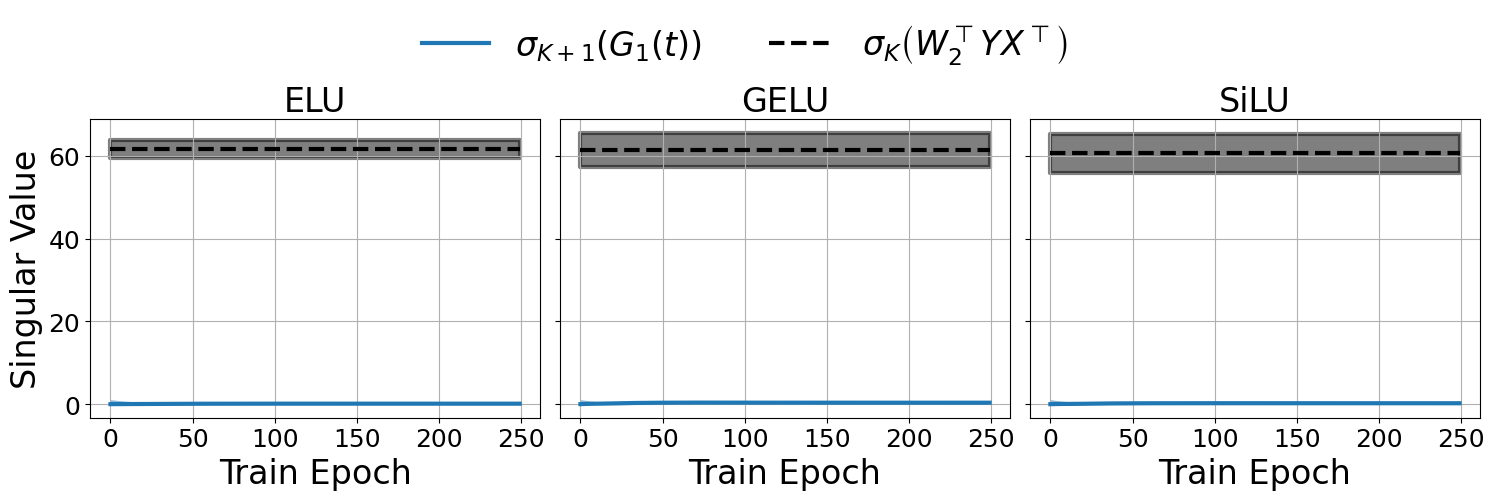

In [12]:
# Mean and stdev of weight decomposition norms across trials
mean_max_tail_sval = np.mean(max_tail_sval, axis=0)
std_max_tail_sval = np.std(max_tail_sval, axis=0)

mean_W2YX_Kth_sval = np.mean(W2YX_Kth_sval, axis=0)
std_W2YX_Kth_sval = np.std(W2YX_Kth_sval, axis=0)


x_range = np.arange(epochs)

n_plots = len(act_fn_strs)
fig, axes = plt.subplots(
    1,
    n_plots,
    figsize=(5 * n_plots, 5),
    sharey=True
)

# Make axes iterable even if n_plots == 1
if n_plots == 1:
    axes = [axes]

legend_handles = None
legend_labels = None

for i, act_fn_str in enumerate(act_fn_strs):
    ax = axes[i]
    
    # Tail singular value of gradient
    label = r'$\sigma_{K + 1}\left( G_1(t) \right)$'
    line, = ax.plot(
        x_range, 
        mean_max_tail_sval[i, :],
        linewidth=3, 
        label=label
    )
    
    ax.fill_between(
        x_range, 
        mean_max_tail_sval[i, :] - std_max_tail_sval[i, :],
        mean_grad_norm_ratio[i, :] + std_max_tail_sval[i, :],
        alpha=0.5
    )
    
    if legend_handles is None:
        legend_handles = []
        legend_labels = []

    if label not in legend_labels:
        legend_handles.append(line)
        legend_labels.append(label)
        
    
    
    # K^th singular value of W2^T YX^T
    label = r'$\sigma_K\left( W_2^\top YX^\top \right)$'
    line, = ax.plot(
        x_range, 
        mean_W2YX_Kth_sval[i] * np.ones(len(x_range)),
        linewidth=3, 
        linestyle='dashed', 
        color='black', 
        label=r'$\sigma_K(W_2^\top YX^\top)$'
    ) 
            
    
    ax.fill_between(
        x_range,    
        mean_W2YX_Kth_sval[i] * np.ones(len(x_range)) - std_W2YX_Kth_sval[i] * np.ones(len(x_range)), 
        mean_W2YX_Kth_sval[i] * np.ones(len(x_range)) + std_W2YX_Kth_sval[i] * np.ones(len(x_range)), 
        linewidth=3, 
        alpha=0.5, 
        color='black'
    ) 

    if legend_handles is None:
        legend_handles = []
        legend_labels = []

    if label not in legend_labels:
        legend_handles.append(line)
        legend_labels.append(label)

    

    ax.set_title(act_fn_str, fontsize=24)
    ax.set_xlabel('Train Epoch', fontsize=24)
    ax.grid(True)
    ax.tick_params(axis='both', labelsize=18)
    #ax.set_yscale('log')

axes[0].set_ylabel('Singular Value', fontsize=24)

# Suptitle
title = '' if whiten_ else 'Unwhitened Data'
fig.suptitle(title, fontsize=28, y=1.0, x=0.525)

# Shared legend below suptitle
fig.legend(
    legend_handles,
    legend_labels,
    loc='upper center',
    bbox_to_anchor=(0.5, 1.025),
    ncol=4,
    fontsize=24,
    frameon=False
)

plt.tight_layout(rect=[0, 0, 1, 0.9])

savefig_dir = './figs/assumptions/'
os.makedirs(savefig_dir, exist_ok=True)

save_fname = 'assumptions_svals'
save_fname += '_unwhitened_data.pdf' if not whiten_ else '.pdf'

if save:
    plt.savefig(os.path.join(savefig_dir, save_fname), bbox_inches='tight')

plt.show()
plt.close()
